# **1. Business Scenario:**
A Bank has a portfolio of 32581 loans distributed across 10 economic sectors.
Lenders lose money when borrowers default. This project builds a classification model that estimates whether a loan applicant is likely to<br>
 **default**  =  **(1)**  or<br>
 **repay**    =  **(0)** <br>
 based on applicant demographics, employment, credit history and loan attributes.
Now, the Risk Management Department wants to:

1. Identify borrowers with a high probability of default (default = 1, not default = 0)
2. Estimate potential Financial Losses.
3. Understand which industries carry the highest Credit Risk.
4. Identify factors influencing borrowers credit ratings.
5. Evaluate how the economic stress affects the loan portfolio.
6. Develop a Machine Learning-based Credit Risk monitoring system.

The bank must decide **whom to lend to, how much, and at what interest rate**. Two errors matter:<br>

| Error | Meaning | Business cost |
|---|---|---|
| False Negative | Risky borrower approved | Direct credit loss |
| False Positive | Good borrower rejected | Lost interest income and customer |

Because defaults are typically the minority class and a missed default is usually costlier than a lost good customer, the project emphasises **recall, precision, ROC-AUC and PR-AUC** rather than accuracy alone.

Using Basel III formula to get Expected Loss : ***EL = PD * LGD * EAD***

# **2. Project Setup and Loading the dataset**

## 2.A> Importing Libraries

In [104]:
import os

# Data Manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical Analysis
from scipy import stats

# Machine Learning
from sklearn.model_selection import(
    train_test_split,
    StratifiedKFold,
    cross_val_score
)
from sklearn.preprocessing import(
    LabelEncoder,
    StandardScaler,
    OneHotEncoder,
    LabelBinarizer
)
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.metrics import(
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    mean_absolute_error,
    mean_squared_error,
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    f1_score
)

# Classification Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import(
    RandomForestRegressor,
    RandomForestClassifier,
    GradientBoostingClassifier,
    ExtraTreesClassifier
)
from sklearn.tree import DecisionTreeClassifier

# pipeline
from imblearn.pipeline import make_pipeline as make_pipeline_imb

from imblearn.over_sampling import SMOTE

# Regression Models
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Model Interpretation
import shap

import warnings
warnings.filterwarnings('ignore')

In [105]:
# Istallation of additional libraries if needed
!pip install xgboost lightgbm catboost shap

## 2.B> Loading the Dataset

In [106]:
df = pd.read_csv("/content/credit_risk_dataset.csv")
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


## 2.C> Understanding the dataset<br>


### 2.C.1> Size of the Dataset

In [107]:
print("Dataset Size:", df.shape)

Dataset Size: (32581, 12)


### 2.C.2> Columns in the Dataset

In [108]:
print("\nColumns:")
print(df.columns.tolist())


Columns:
['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_status', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length']


In [109]:
# Change the column names
df = df.rename(columns={'person_age':'age',
                        'person_income':'income',
                        'person_home_ownership': 'home_ownership',
                        'person_emp_length':'emp_length',
                        'loan_grade':'grade',
                        'loan_int_rate':'int_rate',
                        'cb_person_default_on_file':'default_on_file',
                        'cb_person_cred_hist_length':'cred_hist_length'})
df.columns

Index(['age', 'income', 'home_ownership', 'emp_length', 'loan_intent', 'grade',
       'loan_amnt', 'int_rate', 'loan_status', 'loan_percent_income',
       'default_on_file', 'cred_hist_length'],
      dtype='object')

### 2.C.3> Dataset Info

In [110]:
print("\nData Info:")
print(df.info())


Data Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  32581 non-null  int64  
 1   income               32581 non-null  int64  
 2   home_ownership       32581 non-null  object 
 3   emp_length           31686 non-null  float64
 4   loan_intent          32581 non-null  object 
 5   grade                32581 non-null  object 
 6   loan_amnt            32581 non-null  int64  
 7   int_rate             29465 non-null  float64
 8   loan_status          32581 non-null  int64  
 9   loan_percent_income  32581 non-null  float64
 10  default_on_file      32581 non-null  object 
 11  cred_hist_length     32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB
None


### 2.C.4> Missing values in the dataset

In [111]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
age                       0
income                    0
home_ownership            0
emp_length              895
loan_intent               0
grade                     0
loan_amnt                 0
int_rate               3116
loan_status               0
loan_percent_income       0
default_on_file           0
cred_hist_length          0
dtype: int64


### 2.C.5> Check for duplicate rows

In [112]:
print("\nDuplicate Rows:")
print(df.duplicated().sum())


Duplicate Rows:
165


### 2.C.6> Statistical Summary of the Dataset

In [113]:
# Summary Statistics for Numerical Columns
print("\nSummary Statistics( Numerical Columns):")
print(df.describe())


Summary Statistics( Numerical Columns):
                age        income    emp_length     loan_amnt      int_rate  \
count  32581.000000  3.258100e+04  31686.000000  32581.000000  29465.000000   
mean      27.734600  6.607485e+04      4.789686   9589.371106     11.011695   
std        6.348078  6.198312e+04      4.142630   6322.086646      3.240459   
min       20.000000  4.000000e+03      0.000000    500.000000      5.420000   
25%       23.000000  3.850000e+04      2.000000   5000.000000      7.900000   
50%       26.000000  5.500000e+04      4.000000   8000.000000     10.990000   
75%       30.000000  7.920000e+04      7.000000  12200.000000     13.470000   
max      144.000000  6.000000e+06    123.000000  35000.000000     23.220000   

        loan_status  loan_percent_income  cred_hist_length  
count  32581.000000         32581.000000      32581.000000  
mean       0.218164             0.170203          5.804211  
std        0.413006             0.106782          4.055001  
min

In [114]:
# Summary Statistics for Categorical Columns
print("\nSummary Statistics( Categorical Columns):")
print(df.describe(include="all"))


Summary Statistics( Categorical Columns):
                 age        income home_ownership    emp_length loan_intent  \
count   32581.000000  3.258100e+04          32581  31686.000000       32581   
unique           NaN           NaN              4           NaN           6   
top              NaN           NaN           RENT           NaN   EDUCATION   
freq             NaN           NaN          16446           NaN        6453   
mean       27.734600  6.607485e+04            NaN      4.789686         NaN   
std         6.348078  6.198312e+04            NaN      4.142630         NaN   
min        20.000000  4.000000e+03            NaN      0.000000         NaN   
25%        23.000000  3.850000e+04            NaN      2.000000         NaN   
50%        26.000000  5.500000e+04            NaN      4.000000         NaN   
75%        30.000000  7.920000e+04            NaN      7.000000         NaN   
max       144.000000  6.000000e+06            NaN    123.000000         NaN   

        

# **3. Data Preparation**

## 3.A> Removing Duplicates & restructuring datatypes

In [115]:
df = df.drop_duplicates()

# check the updated dataset
print(df.shape)

(32416, 12)


In [116]:
print(df.duplicated().sum())

0


## 3.B> Handling Mising-Values(Null-Values)

**Missing values in `person_emp_length` column**

In [118]:
# check distribution
print(df['emp_length'].value_counts())

emp_length
0.0      4086
2.0      3832
3.0      3442
5.0      2926
1.0      2897
4.0      2863
6.0      2652
7.0      2186
8.0      1676
9.0      1359
11.0      735
10.0      692
12.0      571
13.0      426
14.0      334
15.0      238
16.0      165
17.0      128
18.0      104
19.0       64
20.0       42
21.0       38
22.0       19
24.0       10
23.0       10
25.0        8
26.0        6
27.0        5
31.0        4
28.0        3
123.0       2
30.0        2
41.0        1
34.0        1
29.0        1
38.0        1
Name: count, dtype: int64


In [119]:
# replace missing values with median
df['emp_length'] = df['emp_length'].fillna(df['emp_length'].median())

# Restructuring the datatype of column 'person_emp_length'
df['emp_length'] = df['emp_length'].astype(int)

In [120]:
df['emp_length'].dtypes

dtype('int64')

**Missing values in `loan_int_rate` column**

In [121]:
# Group-wise median imputation
df['int_rate'] = df.groupby('loan_intent')['int_rate'].transform(lambda x: x.fillna(x.median()))

In [122]:
# Check for null/missing values in the datset again
df.isnull().sum()

,0
age,0
income,0
home_ownership,0
emp_length,0
loan_intent,0
grade,0
loan_amnt,0
int_rate,0
loan_status,0
loan_percent_income,0


## 3.C> Check invalid values and Outliers

In [142]:
# find the maximum of all the numerical columns

df.loc[:, ['age', 'income', 'emp_length', 'loan_amnt', 'int_rate', 'loan_percent_income']].max()

,0
age,144.00
income,6000000.00
emp_length,123.00
loan_amnt,35000.00
int_rate,23.22
loan_percent_income,0.83


From the above results I found some anomalies in this dataset that needed to be checked
```
| Feature |	Maximum |	Observation |
| age |	144 | Impossible age & to be discarded |
| income	| 6,000,000	| Extreme income, creating outlier |
| emp_length |	123	| Impossible and to be discarded |
| loan_amnt	| 35,000	| Needs business-context review |
| int_rate	| 23.22	| High, may not be valid |
| loan_percent_income	| 0.83	| High borrowing burden |
```

Boxplot for Numerical Features:


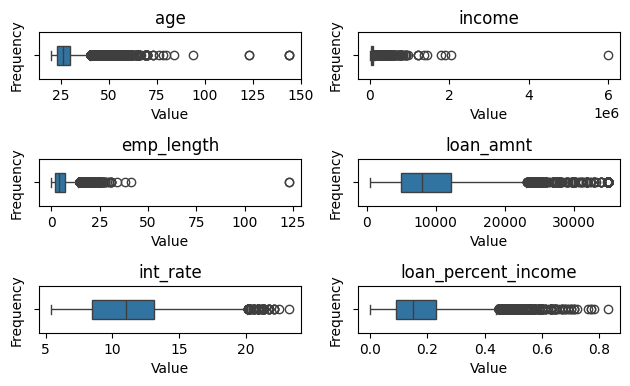

In [124]:
# using boxplot to find the anomalies in the numerical columns

print("Boxplot for Numerical Features:")
boxplot_features = ['age', 'income', 'emp_length', 'loan_amnt', 'int_rate', 'loan_percent_income']
for i, column in enumerate(boxplot_features):
  plt.subplot(4, 2, i+1)
  sns.boxplot(x=df[column], width=0.4)
  plt.title(column)
  plt.xlabel('Value')
  plt.ylabel('Frequency')
  plt.tight_layout()
plt.show()

## 3D> Removing Outliers

In [126]:
# From "person_age" column
# Keep only rows where age is between 18 and 80
df_clean = df[(df['age'] >= 18) & (df['age'] <= 80)].copy()

# Check how many rows were removed
print(f"Removed {len(df) - len(df_clean)} rows")

Removed 7 rows


In [128]:
# From "person_income" column
# Removing the extreme income of 6000000
df_clean = df_clean[df_clean['income'] < 6000000]

# Check how many rows were removed
print(f"Removed {len(df) - len(df_clean)} rows")

Removed 7 rows


In [129]:
# From "person_emp_length" Column
# Keep only rows where employment length is 60 years or less (removing the impossible 123 years anomaly)
df_clean = df_clean[df_clean['emp_length'] <= 60]

# Check how many rows were removed
print(f"Removed {len(df) - len(df_clean)} rows")
# Check how many rows were removed in this step
print(f"New dataset size: {df_clean.shape}")

Removed 9 rows
New dataset size: (32407, 14)


In [143]:
df_clean.loc[:, ['age', 'income', 'emp_length', 'loan_amnt', 'int_rate', 'loan_percent_income']].max()

,0
age,80.00
income,2039784.00
emp_length,41.00
loan_amnt,35000.00
int_rate,23.22
loan_percent_income,0.83


## 3.E> IQR - Skewness and Kurtosis

In [191]:
bin_cols = ["default_on_file"]
for c in bin_cols:
    if c in df_clean.columns and not pd.api.types.is_numeric_dtype(df_clean[c]):
        df_clean[c] = df_clean[c].map({"Y": 1, "N": 0})

def iqr_outlier_share(s):
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    if iqr == 0:
        return 0.0
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean()

# Properly define numerical columns present in the dataset
num_cols = ['age', 'income', 'emp_length', 'loan_amnt', 'int_rate', 'loan_status', 'loan_percent_income', 'cred_hist_length']
present_num_cols = [col for col in num_cols if col in df_clean.columns]

# Create and display IQR, Skew, and Kurtosis Summary
summary_df = pd.DataFrame({
    "IQR": df_clean[present_num_cols].quantile(0.75) - df_clean[present_num_cols].quantile(0.25),
    "skew": df_clean[present_num_cols].skew(),
    "kurtosis": df_clean[present_num_cols].kurtosis(),
    "iqr_outlier_share": df_clean[present_num_cols].apply(iqr_outlier_share)
}).round(3)

display(summary_df)

def add_features(dataframe):
    dataframe = dataframe.copy()
    dataframe["loan_to_income"] = dataframe.loan_amnt / dataframe.income
    dataframe["income_to_age"] = dataframe.income / dataframe.age
    dataframe["income_to_loan"] = dataframe.income / dataframe.loan_amnt
    return dataframe

# Drop rows where target is missing to avoid potential casting issues
if "loan_status" in df_clean.columns:
    df_clean = df_clean.dropna(subset=["loan_status"])
    y = df_clean.pop("loan_status")

df_clean = add_features(df_clean)

print(f"Target extracted. Final features shape: {df_clean.shape}")

,IQR,skew,kurtosis,iqr_outlier_share
age,7.00,1.901,5.364,0.046
income,40700.00,9.778,226.085,0.045
emp_length,5.00,1.281,2.589,0.026
loan_amnt,7250.00,1.191,1.419,0.052
int_rate,4.62,0.218,-0.427,0.002
loan_percent_income,0.14,1.063,1.215,0.020
cred_hist_length,5.00,1.655,3.685,0.035


Target extracted. Final features shape: (32407, 15)


**Observations:**<br>

* **`age`**: Heavily right-skewed - While only 4.5% are flagged as outliers, a few ultra-high earners are drastically pulling the tail to the right (causing the massive kurtosis of 226).
* **`income`**: Moderately right-skewed - Most borrowers are younger, with a smaller tail of older applicants.
* **`emp_length`**: Right-skewed - Most applicants have short credit histories, with a smaller group having decades of history.
* **`loan_amnt`**: Right-skewed - Most borrowers have been at their current job for a relatively short time, with a tail of long-tenured employees.
* **`int_rate`**: Right-skewed - Most loans are small-to-moderate, with a noticeable group of large loans.
* **`loan_percent_income`**: Moderately right-skewed. Most people borrow a small fraction of their income, with a tail of high-burden loans.
* **`cred_hist_length`**: Nearly normal / well-behaved. Very symmetrical, almost no outliers, and flat tails.



In [137]:
# Profile categorical features instead of calculating IQR (which is mathematically invalid for strings)
cat_cols = [col for col in df_clean.columns if col not in num_cols]

# Calculate unique counts and frequency/share of the most common class (mode dominance)
cat_profile = pd.DataFrame({
    "unique_values": df_clean[cat_cols].nunique(),
    "most_frequent_value": df_clean[cat_cols].mode().iloc[0],
    "most_frequent_share": df_clean[cat_cols].apply(lambda s: s.value_counts(normalize=True).values[0]).round(3)
})

display(cat_profile)

,unique_values,most_frequent_value,most_frequent_share
home_ownership,4,RENT,0.505
loan_intent,6,EDUCATION,0.198
grade,7,A,0.330
default_on_file,2,0,0.823
loan_to_income,9910,0.2,0.016
income_to_age,8661,2000.0,0.011
income_to_loan,9910,5.0,0.016


# **4. EDA**

## 4.A> Target variable distribution

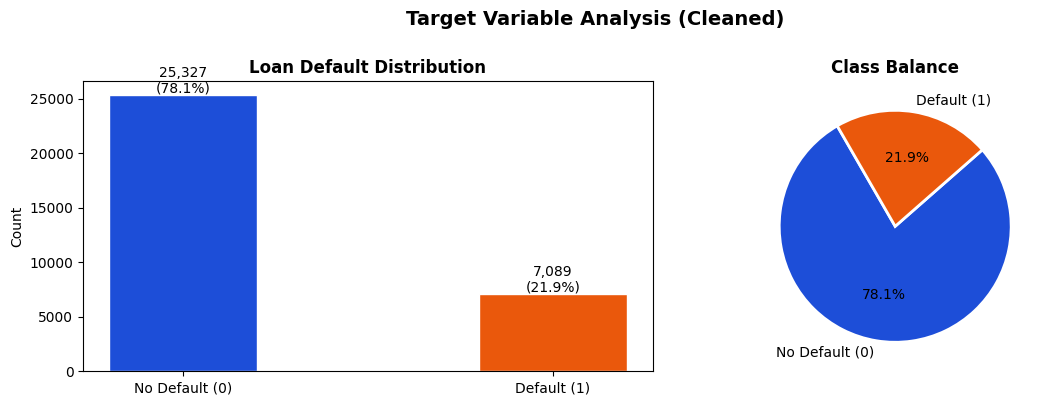


 Insight: Dataset is imbalanced — 21.9% defaults.

 This means a naive model predicting "no default" would get 78.1% accuracy.


In [153]:
# Target variable distribution using the extracted 'y' variable
counts = y.value_counts()
labels = ['No Default (0)', 'Default (1)']

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bar chart
axes[0].bar(labels, counts.values, color=['#1D4ED8', '#EA580C'], edgecolor='white', width=0.4)
axes[0].set_title('Loan Default Distribution', fontweight='bold')
axes[0].set_ylabel('Count')
for i, val in enumerate(counts.values):
    axes[0].text(i, val + 200, f'{val:,}\n({val/len(y)*100:.1f}%)', ha='center', fontsize=10)

# Pie chart
axes[1].pie(counts.values, labels=labels, autopct='%1.1f%%',
colors=['#1D4ED8', '#EA580C'], startangle=120,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Class Balance', fontweight='bold')

plt.suptitle('Target Variable Analysis (Cleaned)', fontsize=14, fontweight='bold', y = 1.00)
plt.tight_layout()
plt.show()

print(f'\n Insight: Dataset is imbalanced — {counts[1]/len(y)*100:.1f}% defaults.')
print(f'\n This means a naive model predicting "no default" would get {100 - counts[1]/len(y)*100:.1f}% accuracy.')

**Observation:**<br>
There is a class imbalance in the target column. We will deal with it using SMOTE while building our model later in this notebook.

**Observing Age Values**

In [138]:
print("Observing age values")
df_clean['age'].describe()

Observing age values


,age
count,32407.000000
mean,27.726973
std,6.191831
min,20.000000
25%,23.000000
50%,26.000000
75%,30.000000
max,80.000000


In [139]:
def age_group(person_age):
  if person_age < 18:
    return 'less than 18'
  elif person_age >= 18 and person_age < 25:
    return 'Entry level(18-24):'
  elif person_age >= 25 and person_age <34:
    return 'Early Career(25-33):'
  elif person_age >= 34 and person_age < 45:
    return 'Mid Career(34-44):'
  elif person_age >= 45 and person_age < 55:
    return 'Senior Career(15-54):'
  elif person_age >=55 and person_age <= 60:
    return 'Pre Retirement(55-60):'
  else:
    return "Retired"

print("Observing age group")
df_clean['age_group'] = df_clean['age'].apply(age_group)
print(df_clean['age_group'].value_counts())


Observing age group
age_group
Early Career(25-33):      15407
Entry level(18-24):       12220
Mid Career(34-44):         4028
Senior Career(15-54):       600
Pre Retirement(55-60):       89
Retired                      63
Name: count, dtype: int64


**Countplot for numerical columns**

Countplot for Numerical features


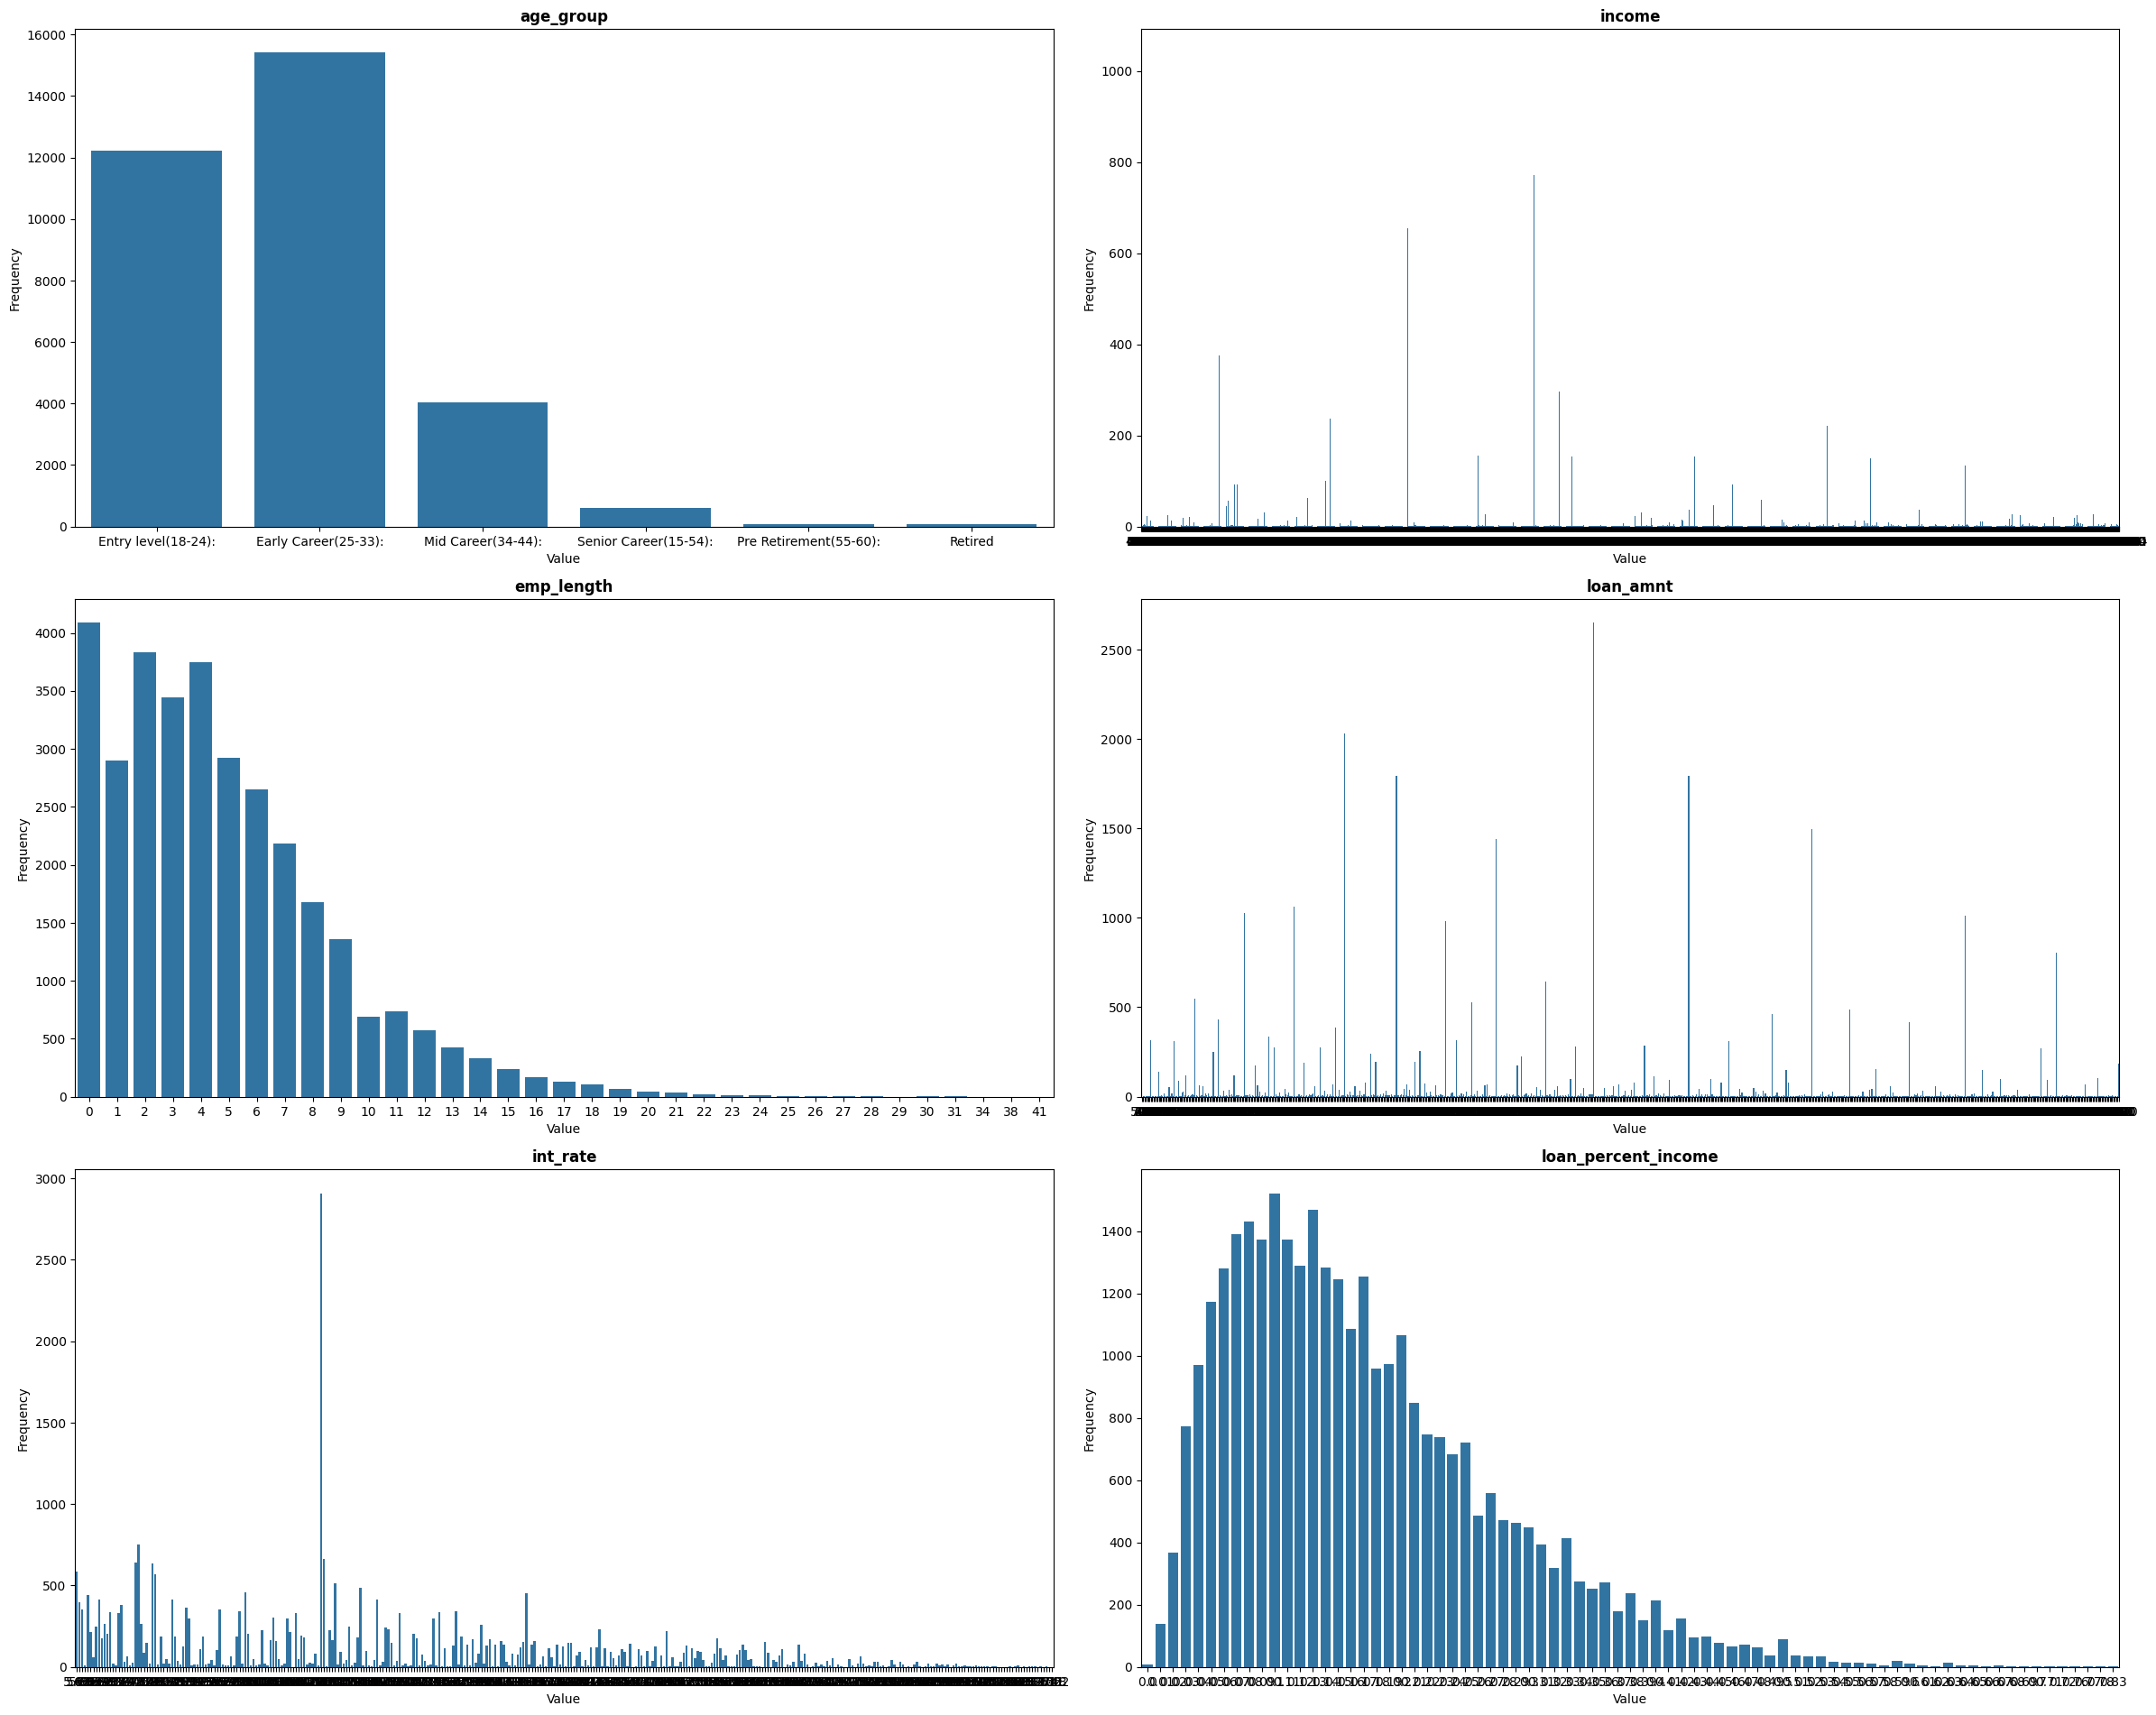

In [160]:
print("Countplot for Numerical features")
plt.figure(figsize=(24,25))
countplot_features = ['age_group', 'income', 'emp_length', 'loan_amnt', 'int_rate', 'loan_percent_income']
for i, column in enumerate(countplot_features):
  plt.subplot(4, 2, i+1)
  sns.countplot(x=df_clean[column])
  plt.title(column, fontweight= 'bold')
  plt.xlabel('Value')
  plt.ylabel('Frequency')
  plt.tight_layout()

**Observation:**<br>
* There are more customers in their Early Career(25-34 years) and Entry level(18-24 years) than any other age group.<br>
* Income is mostly equally distributed except one.<br>
* Age, Employment Length, Loan_percent_income graph is right-skewed.<br>
* Loan amount has a normal distribution except few entries which can be normal.<br>
* loan interest rates are evenly distributed except one entry.<br>


## 4.B> Univariate Analysis

### 4.B.1> Histogram for numerical column

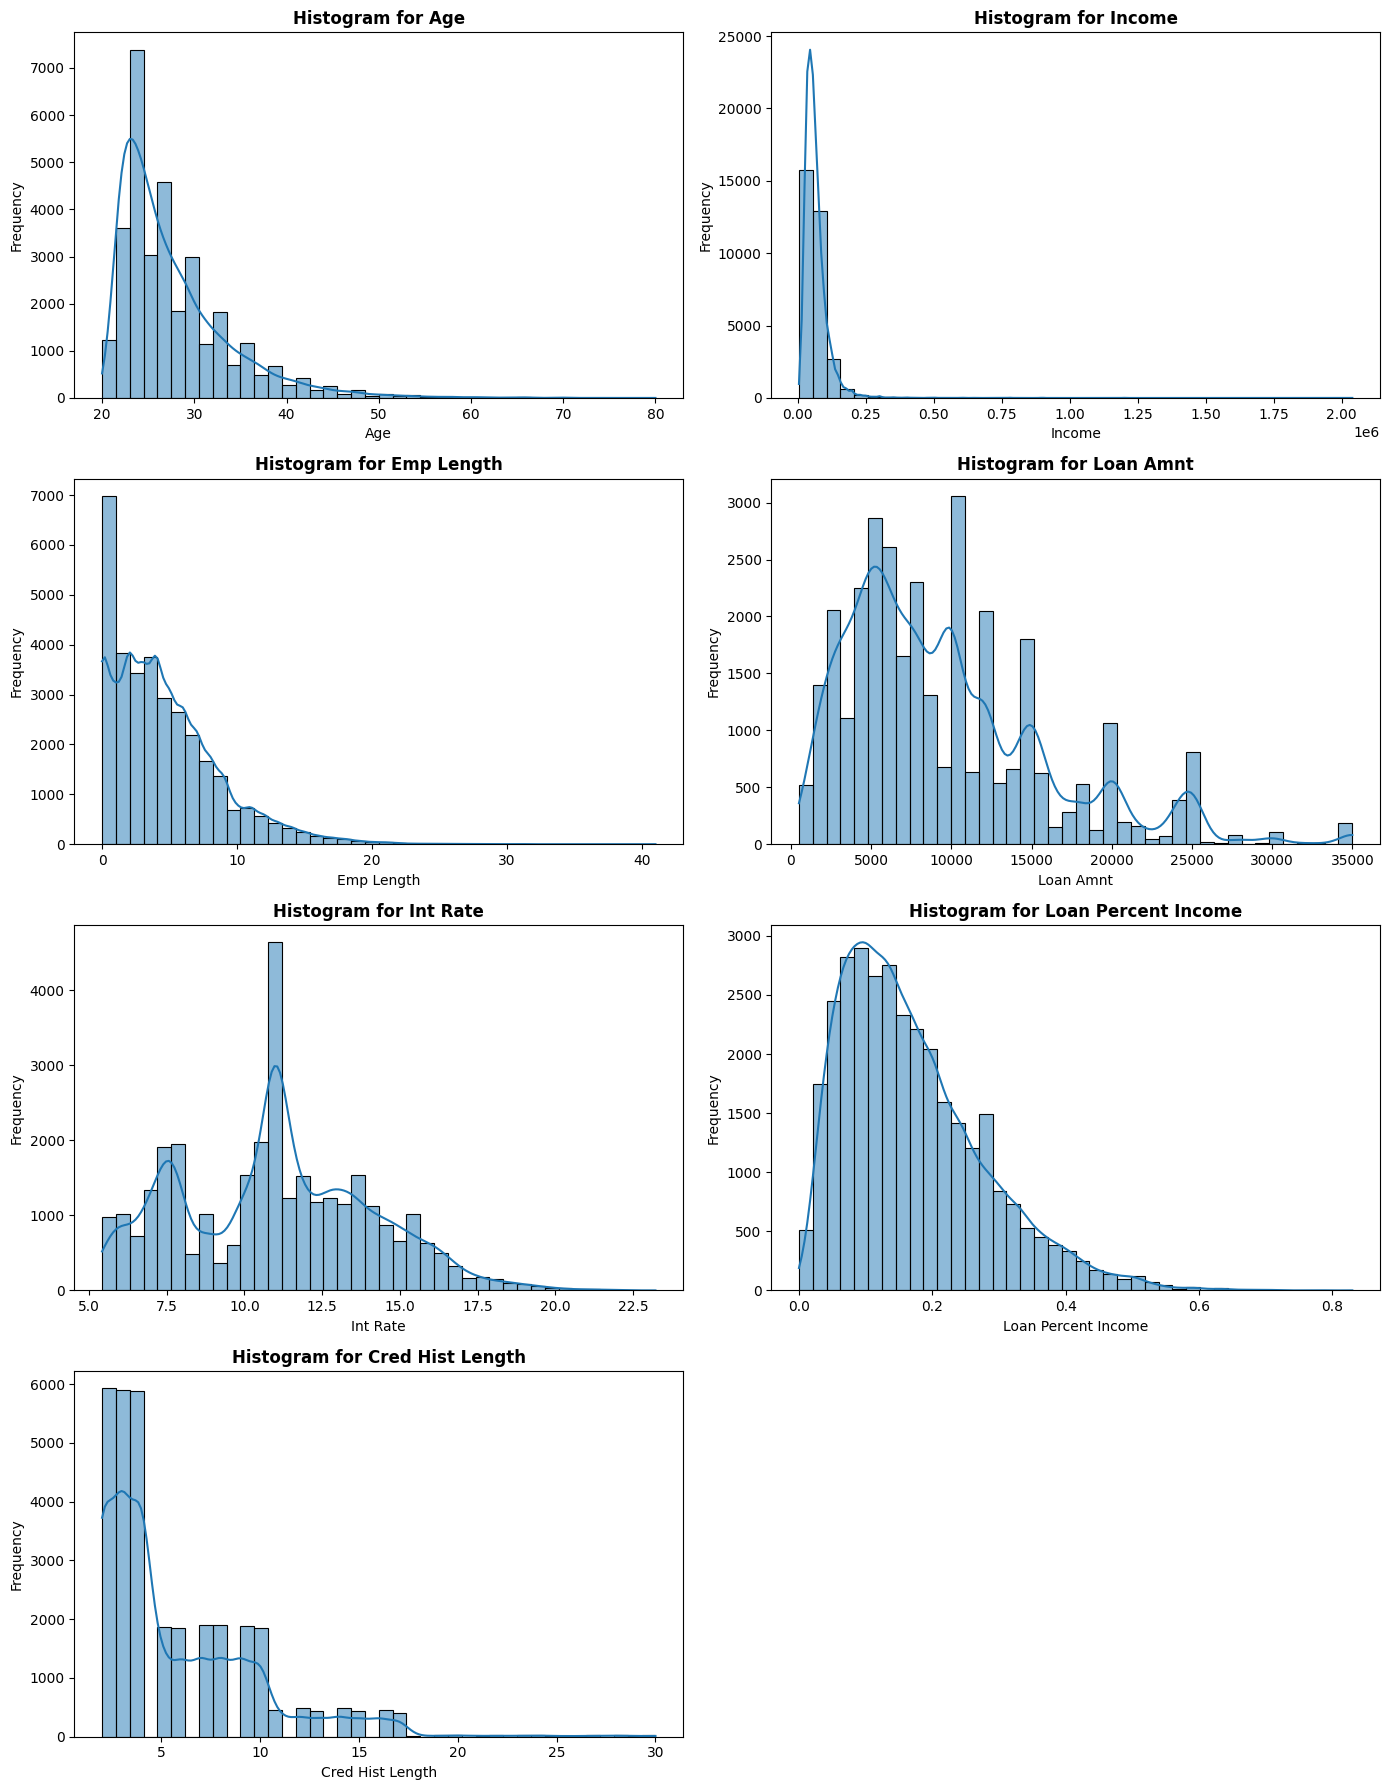

In [171]:
# Select numerical columns
num_cols = ['age', 'income', 'emp_length', 'loan_amnt', 'int_rate', 'loan_percent_income', 'cred_hist_length']

# Subplot layout
fig, axes = plt.subplots(4, 2, figsize=(14, 18))
axes = np.array(axes).flatten()

# Plot histogram for each numerical column
for i, col in enumerate(num_cols):
    sns.histplot(data=df_clean, x=col, bins=40, ax=axes[i], kde=True)
    axes[i].set_title(f'Histogram for {col.replace("_", " ").title()}', fontweight='bold')
    axes[i].set_xlabel(col.replace("_", " ").title())
    axes[i].set_ylabel('Frequency')

# Remove unused subplots
for i in range(len(num_cols), len(axes)):
    fig.delaxes(axes[i])

# Adjust layout and display the plot
plt.tight_layout()
plt.show()

### 4.B.2> Histogram for Categorical columns

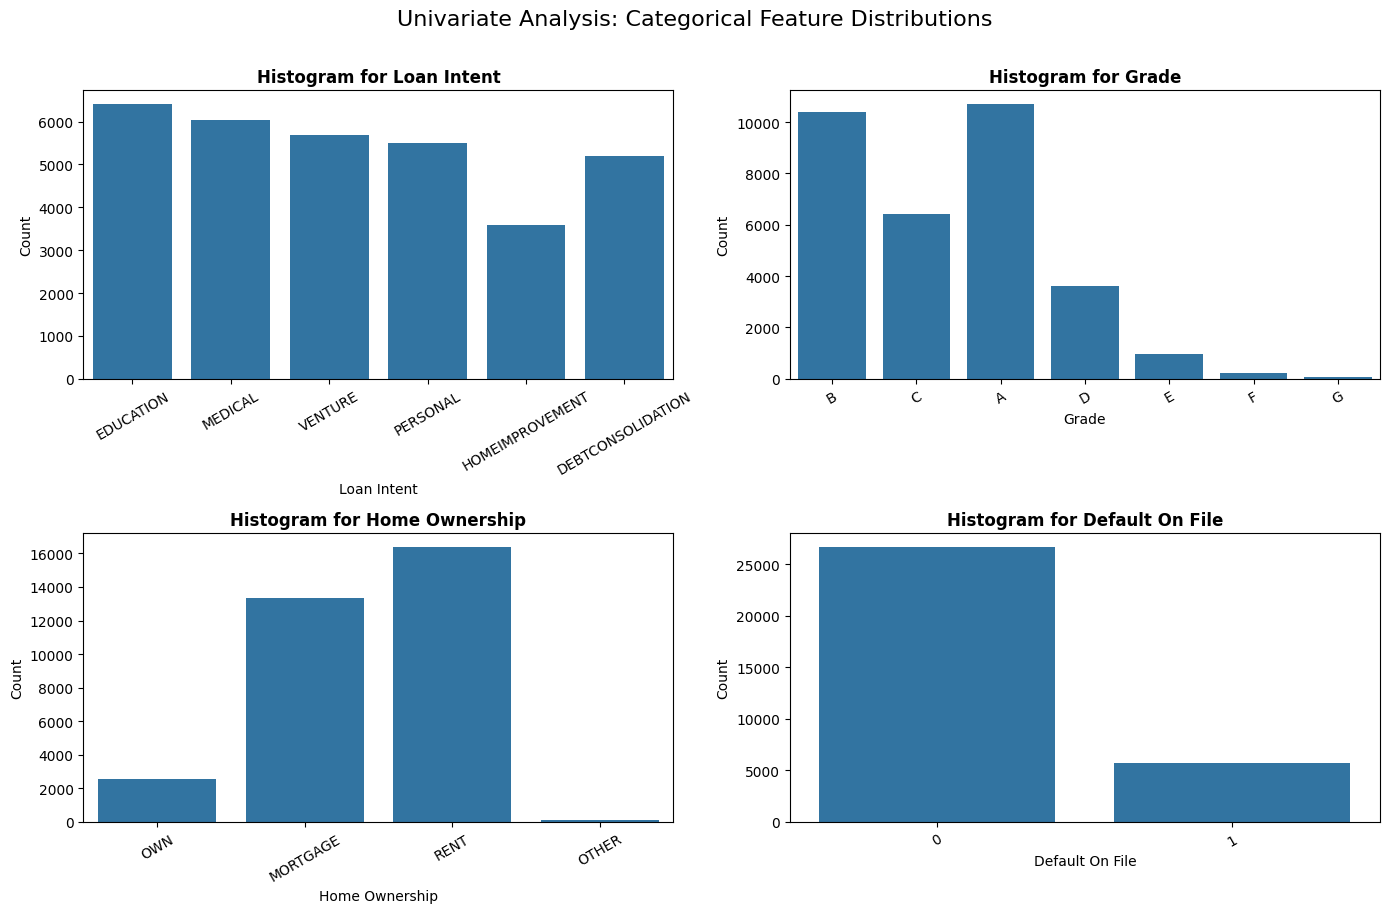

In [186]:
# Identify Categorical column
cat_cols = ['loan_intent', 'grade', 'home_ownership', 'default_on_file']

# Set subplot layout
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

# Flatten axes for easy iteration
axes = np.array(axes).flatten()

# Plot each categorical columns
for i, col in enumerate(cat_cols):
    sns.countplot(data=df_clean, x=col, ax=axes[i])
    axes[i].set_title(f'Histogram for {col.replace("_", " ").title()}', fontweight='bold')
    axes[i].set_xlabel(col.replace("_", " ").title())
    axes[i].set_ylabel('Count')
    axes[i].tick_params(axis='x', rotation=30)

plt.suptitle("Univariate Analysis: Categorical Feature Distributions",fontsize=16,y=1.01)

plt.tight_layout()
plt.show()

### 4.B.3> Summary table: mean, median, min, max, iqr, skew, kurtosis, iqr_outlier_share

In [192]:
num_cols = ['age', 'income', 'emp_length', 'loan_amnt', 'int_rate', 'loan_status', 'loan_percent_income', 'cred_hist_length']
present_num_cols = [col for col in num_cols if col in df_clean.columns]
# Create and display IQR, Skew, and Kurtosis Summary
summary_df = pd.DataFrame({
    "mean": df_clean[present_num_cols].mean(),
    "median": df_clean[present_num_cols].median(),
    "min": df_clean[present_num_cols].min(),
    "max": df_clean[present_num_cols].max(),
    "IQR": df_clean[present_num_cols].quantile(0.75) - df_clean[present_num_cols].quantile(0.25),
    "skew": df_clean[present_num_cols].skew(),
    "kurtosis": df_clean[present_num_cols].kurtosis(),
    "iqr_outlier_share": df_clean[present_num_cols].apply(iqr_outlier_share)
}).round(3)

display(summary_df)


,mean,median,min,max,IQR,skew,kurtosis,iqr_outlier_share
age,27.727,26.00,20.00,80.00,7.00,1.901,5.364,0.046
income,65894.678,55000.00,4000.00,2039784.00,40700.00,9.778,226.085,0.045
emp_length,4.762,4.00,0.00,41.00,5.00,1.281,2.589,0.026
loan_amnt,9592.570,8000.00,500.00,35000.00,7250.00,1.191,1.419,0.052
int_rate,11.017,10.99,5.42,23.22,4.62,0.218,-0.427,0.002
loan_percent_income,0.170,0.15,0.00,0.83,0.14,1.063,1.215,0.020
cred_hist_length,5.810,4.00,2.00,30.00,5.00,1.655,3.685,0.035


## 4.C> Bivariate Analysis